# Hari 2b — Estimasi Kovarians & Portofolio Varians Minimum: Wishart, Marchenko–Pastur, Ledoit–Wolf

> **Tanggal:** 2026-11-20 · **Jenis:** `quant` · **Topik:** Bonus / Off-Roadmap

## Tujuan & Intuisi Teoretis
Dalam optimisasi portofolio varians minimum global (**GMV**), bobot optimal bergantung pada invers matriks kovarians $\Sigma^{-1}$:
$$w_{\text{GMV}} = \frac{\Sigma^{-1}\mathbf{1}}{\mathbf{1}^T \Sigma^{-1} \mathbf{1}}, \qquad \Sigma_{\min} = \frac{1}{\mathbf{1}^T \Sigma^{-1} \mathbf{1}}.$$

Ketika $\Sigma$ diganti dengan kovarians sampel $S$ dari $T$ observasi atas $N$ aset ($r_t \sim \mathcal{N}(\mu, \Sigma)$), matriks $(T-1)S$ mengikuti distribusi **Wishart** $\mathcal{W}_N(T-1, \Sigma)$. Karena proses optimisasi mengeksploitasi *noise* sampel untuk menekan varians historis:
1. **Estimasi *in-sample* terlalu optimistis** (Muirhead, 1982):
   $$\frac{\hat{\sigma}^2}{\Sigma_{\min}} = \frac{(\mathbf{1}^T \Sigma^{-1} \mathbf{1})}{(\mathbf{1}^T S^{-1} \mathbf{1})} \sim \frac{\chi^2_{T-N}}{T-1} \implies \mathbb{E}\left[\frac{\hat{\sigma}^2}{\Sigma_{\min}}\right] = \frac{T-N}{T-1} < 1.$$
2. **Risiko *out-of-sample* (*realized*) justru membengkak** (Okhrin & Schmid, 2006):
   $$\mathbb{E}\left[\frac{w_S^T \Sigma w_S}{\Sigma_{\min}}\right] = \frac{T-2}{T-N-1} > 1.$$
3. Ketika rasio dimensi $q = N/T$ membesar, nilai eigen $S$ melebar mengikuti hukum **Marchenko–Pastur** $[ (1-\sqrt{q})^2, (1+\sqrt{q})^2 ]$, sehingga kondisi matriks memburuk dan *shrinkage* **Ledoit–Wolf** menjadi krusial.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from qb100 import covariance as cov
from qb100 import plotting

plotting.set_style()
t_start_all = time.perf_counter()

N, T, K, M = 50, 200, 3, 5000
Sigma_true, mu = cov.generate_factor_model(n_assets=N, n_factors=K, seed=42)
w_true_gmv, Sigma_min = cov.gmv_closed_form(Sigma_true)

print(f"N = {N}, T = {T}, K = {K}, M = {M}")
print(f"Sigma_min sejati = {Sigma_min:.8f}")
print(f"Condition number Sigma_true = {np.linalg.cond(Sigma_true):.2f}")

N = 50, T = 200, K = 3, M = 5000
Sigma_min sejati = 0.00067839
Condition number Sigma_true = 55.18


## 1–3. Teorema Wishart, Varians *Out-of-Sample* & Shrinkage Ledoit–Wolf ($M = 5000$)
Kita jalankan $M = 5000$ percobaan Monte Carlo tervektorisasi penuh (tanpa loop Python per percobaan di bagian panas).

In [2]:
exp = cov.run_wishart_lw_experiment(Sigma_true, mu, n_obs=T, n_trials=M, batch_size=500, seed=42)

in_r = exp["in_sample_ratio"]
re_r = exp["realized_sample_ratio"]
lw_r = exp["realized_lw_ratio"]
intens = exp["lw_intensity"]

theo_in_mean = (T - N) / (T - 1)
theo_in_var = 2.0 * (T - N) / ((T - 1) ** 2)
theo_re_mean = (T - 2) / (T - N - 1)

def summarize(arr):
    mean = float(np.mean(arr))
    var = float(np.var(arr, ddof=1))
    se = float(np.sqrt(var / len(arr)))
    return mean, var, se, mean - 1.96 * se, mean + 1.96 * se

in_m, in_v, in_se, in_lo, in_hi = summarize(in_r)
re_m, re_v, re_se, re_lo, re_hi = summarize(re_r)
lw_m, lw_v, lw_se, lw_lo, lw_hi = summarize(lw_r)
lw_better_pct = float(np.mean(lw_r < re_r) * 100.0)

summary_df = pd.DataFrame([
    {"Metrik": "In-sample S (sigma_hat^2 / Sigma_min)", "Empiris": in_m, "SE": in_se,
     "CI 95%": f"[{in_lo:.4f}, {in_hi:.4f}]", "Teori": theo_in_mean, "z-score": abs(in_m - theo_in_mean) / in_se},
    {"Metrik": "Realized S (w_S^T Sigma w_S / Sigma_min)", "Empiris": re_m, "SE": re_se,
     "CI 95%": f"[{re_lo:.4f}, {re_hi:.4f}]", "Teori": theo_re_mean, "z-score": abs(re_m - theo_re_mean) / re_se},
    {"Metrik": "Realized LW (w_LW^T Sigma w_LW / Sigma_min)", "Empiris": lw_m, "SE": lw_se,
     "CI 95%": f"[{lw_lo:.4f}, {lw_hi:.4f}]", "Teori": np.nan, "z-score": np.nan},
])
print(f"Varians in-sample: empiris={in_v:.6f} vs teori={theo_in_var:.6f}")
print(f"Intensitas LW rata-rata: {np.mean(intens):.4f} | LW lebih baik dari S: {lw_better_pct:.2f}% percobaan")
summary_df

Varians in-sample: empiris=0.007520 vs teori=0.007576
Intensitas LW rata-rata: 0.0462 | LW lebih baik dari S: 100.00% percobaan


,Metrik,Empiris,SE,CI 95%,Teori,z-score
0,In-sample S (sigma_hat^2 / Sigma_min),0.754106,0.001226,"[0.7517, 0.7565]",0.753769,0.275163
1,Realized S (w_S^T Sigma w_S / Sigma_min),1.327673,0.001065,"[1.3256, 1.3298]",1.328859,1.114334
2,Realized LW (w_LW^T Sigma w_LW / Sigma_min),1.233450,0.000711,"[1.2321, 1.2348]",NaN,NaN


Intensitas tunggal (T=200, N=50) : 0.045255 (dalam [0, 1])
Intensitas asimtotik (T=20000, N=10): 0.000469 (-> 0)
Selisih trace(Sigma_LW) - trace(S_T): 8.882e-16
Min eigenvalue Sigma_LW: 0.012641 (> 0)


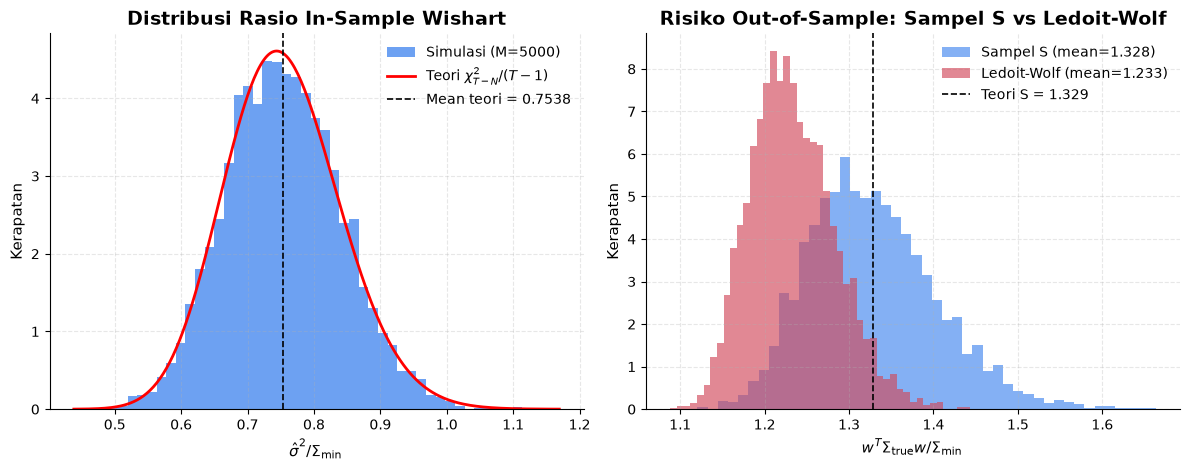

In [3]:
# Verifikasi sifat analitik Ledoit-Wolf (target identitas)
rets_single = cov.simulate_returns(mu, Sigma_true, n_obs=T, n_trials=1, seed=42)[0]
s_t_single = cov.sample_covariance(rets_single, ddof=0)
sigma_lw_single, alpha_single = cov.ledoit_wolf(rets_single)

sigma_true_10, mu_10 = cov.generate_factor_model(n_assets=10, n_factors=3, seed=42)
rets_large = cov.simulate_returns(mu_10, sigma_true_10, n_obs=20_000, n_trials=1, seed=42)[0]
_, alpha_large = cov.ledoit_wolf(rets_large)

print(f"Intensitas tunggal (T=200, N=50) : {alpha_single:.6f} (dalam [0, 1])")
print(f"Intensitas asimtotik (T=20000, N=10): {alpha_large:.6f} (-> 0)")
print(f"Selisih trace(Sigma_LW) - trace(S_T): {np.trace(sigma_lw_single) - np.trace(s_t_single):.3e}")
print(f"Min eigenvalue Sigma_LW: {np.min(np.linalg.eigvalsh(sigma_lw_single)):.6f} (> 0)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ax = axes[0]
ax.hist(in_r, bins=45, density=True, alpha=0.65, label="Simulasi (M=5000)")
xg = np.linspace(in_r.min() * 0.95, in_r.max() * 1.05, 300)
ax.plot(xg, (T - 1) * stats.chi2.pdf(xg * (T - 1), df=T - N), "r-", lw=2, label=r"Teori $\chi^2_{T-N}/(T-1)$")
ax.axvline(theo_in_mean, color="k", ls="--", lw=1.2, label=f"Mean teori = {theo_in_mean:.4f}")
ax.set_title("Distribusi Rasio In-Sample Wishart")
ax.set_xlabel(r"$\hat{\sigma}^2 / \Sigma_{\min}$")
ax.set_ylabel("Kerapatan")
ax.legend()

ax = axes[1]
ax.hist(re_r, bins=45, density=True, alpha=0.55, label=f"Sampel S (mean={re_m:.3f})")
ax.hist(lw_r, bins=45, density=True, alpha=0.65, label=f"Ledoit-Wolf (mean={lw_m:.3f})")
ax.axvline(theo_re_mean, color="k", ls="--", lw=1.2, label=f"Teori S = {theo_re_mean:.3f}")
ax.set_title("Risiko Out-of-Sample: Sampel S vs Ledoit-Wolf")
ax.set_xlabel(r"$w^T \Sigma_{\mathrm{true}} w / \Sigma_{\min}$")
ax.set_ylabel("Kerapatan")
ax.legend()

plt.tight_layout()
plotting.save_figure(fig, "day002b_wishart-lw")
plt.show()

## 4. Spektrum Marchenko–Pastur ($\Sigma = I$, $q = 0.25$ dan $q = 0.50$)
Untuk data Gaussian murni $N(0, I)$, nilai eigen matriks korelasi sampel terkonsentrasi dalam $[ (1-\sqrt{q})^2, (1+\sqrt{q})^2 ]$ dengan fluktuasi tepi orde Tracy–Widom $\mathcal{O}(N^{-2/3})$.

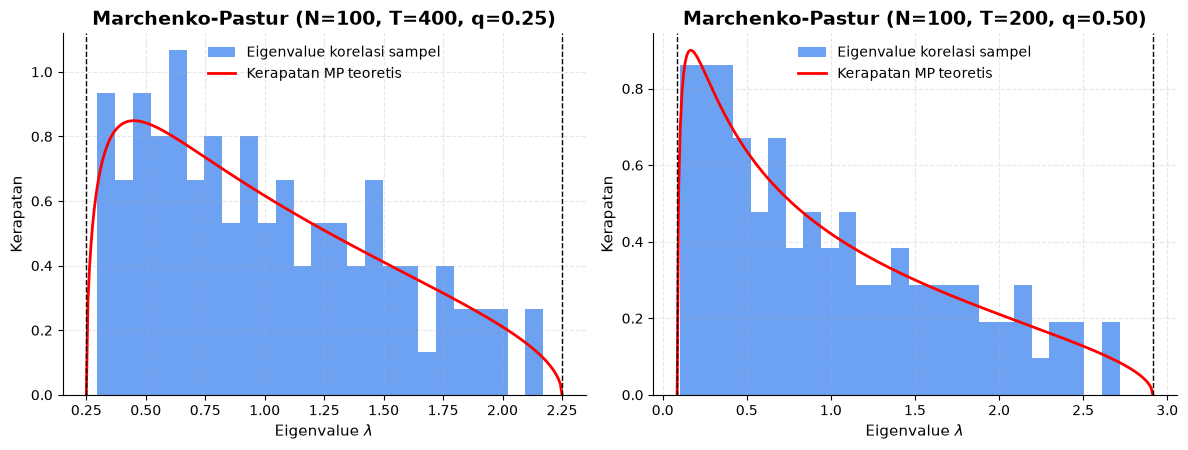

,N,T,q,MP min,Eig min,MP max,Eig max,TW N^(-2/3)
0,100,400,0.25,0.250000,0.296278,2.250000,2.171396,0.046416
1,100,200,0.50,0.085786,0.105489,2.914214,2.716552,0.046416


In [4]:
mp_configs = [(100, 400, 0.25), (100, 200, 0.50)]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
mp_rows = []

for ax, (n_mp, t_mp, q_mp) in zip(axes, mp_configs):
    eigs = cov.sample_correlation_eigenvalues(n_assets=n_mp, n_obs=t_mp, seed=42)
    l_min, l_max = cov.marchenko_pastur_bounds(q_mp)
    tw_tol = n_mp ** (-2.0 / 3.0)
    mp_rows.append({
        "N": n_mp, "T": t_mp, "q": q_mp,
        "MP min": l_min, "Eig min": float(eigs.min()),
        "MP max": l_max, "Eig max": float(eigs.max()),
        "TW N^(-2/3)": tw_tol,
    })
    ax.hist(eigs, bins=25, density=True, alpha=0.65, label="Eigenvalue korelasi sampel")
    xg = np.linspace(l_min, l_max, 300)
    ax.plot(xg, cov.marchenko_pastur_pdf(xg, q_mp), "r-", lw=2, label="Kerapatan MP teoretis")
    ax.axvline(l_min, color="k", ls="--", lw=1)
    ax.axvline(l_max, color="k", ls="--", lw=1)
    ax.set_title(f"Marchenko-Pastur (N={n_mp}, T={t_mp}, q={q_mp:.2f})")
    ax.set_xlabel(r"Eigenvalue $\lambda$")
    ax.set_ylabel("Kerapatan")
    ax.legend()

plt.tight_layout()
plotting.save_figure(fig, "day002b_marchenko-pastur")
plt.show()
pd.DataFrame(mp_rows)

## 5. Sapuan Rasio Dimensi $q = N/T$ ($N \in \{10, 25, 50, 100, 150\}$, $T = 200$, $M = 2000$)
Saat $N$ mendekati $T$, estimator sampel $S$ menjadi sangat buruk terkondisi dan rasio *realized* meledak mengikuti $\frac{T-2}{T-N-1}$ (mencapai $\approx 4.04$ pada $N = 150$).

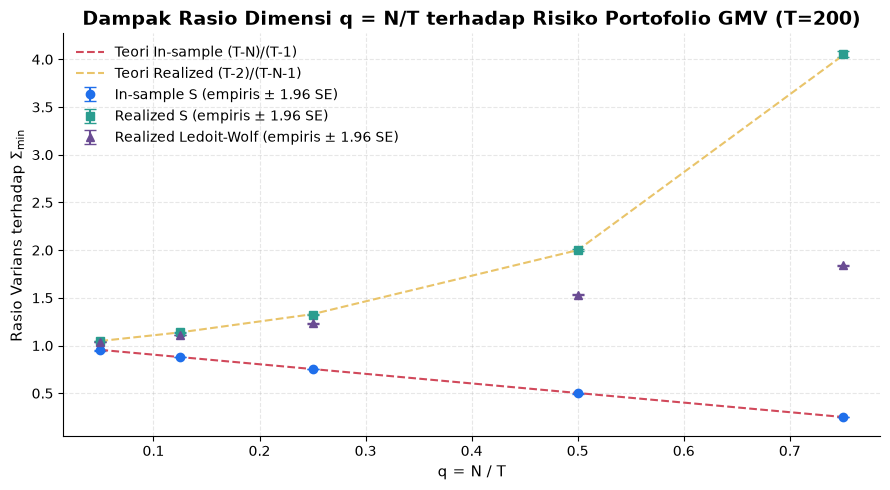

,n,q,in_sample_mean,in_sample_theo,realized_mean,realized_theo,lw_realized_mean,cond_true,cond_sample
0,10,0.050,0.950201,0.954774,1.047805,1.047619,1.040850,12.323752,17.086749
1,25,0.125,0.880414,0.879397,1.137805,1.137931,1.108467,27.184515,50.420028
2,50,0.250,0.753140,0.753769,1.324672,1.328859,1.231539,55.181611,145.046637
3,100,0.500,0.499318,0.502513,2.004413,2.000000,1.533983,113.998711,1015.977264
4,150,0.750,0.250599,0.251256,4.051601,4.040816,1.842661,169.617743,5958.553195


In [5]:
q_rows = cov.run_q_sweep(n_grid=(10, 25, 50, 100, 150), n_obs=200, n_trials=2000, seed=42)
q_df = pd.DataFrame(q_rows)

fig, ax = plt.subplots(figsize=(9, 5))
q_vals = q_df["q"].values
ax.errorbar(q_vals, q_df["in_sample_mean"], yerr=1.96 * q_df["in_sample_se"],
            fmt="o", capsize=4, label="In-sample S (empiris ± 1.96 SE)")
ax.plot(q_vals, q_df["in_sample_theo"], "--", label="Teori In-sample (T-N)/(T-1)")
ax.errorbar(q_vals, q_df["realized_mean"], yerr=1.96 * q_df["realized_se"],
            fmt="s", capsize=4, label="Realized S (empiris ± 1.96 SE)")
ax.plot(q_vals, q_df["realized_theo"], "--", label="Teori Realized (T-2)/(T-N-1)")
ax.errorbar(q_vals, q_df["lw_realized_mean"], yerr=1.96 * q_df["lw_realized_se"],
            fmt="^", capsize=4, label="Realized Ledoit-Wolf (empiris ± 1.96 SE)")
ax.set_title("Dampak Rasio Dimensi q = N/T terhadap Risiko Portofolio GMV (T=200)")
ax.set_xlabel("q = N / T")
ax.set_ylabel(r"Rasio Varians terhadap $\Sigma_{\min}$")
ax.legend()
plt.tight_layout()
plotting.save_figure(fig, "day002b_q-sweep")
plt.show()
q_df[["n", "q", "in_sample_mean", "in_sample_theo", "realized_mean", "realized_theo", "lw_realized_mean", "cond_true", "cond_sample"]]

## 6. GMV Tertutup vs Numerik & Frontier *Long-Only*
Kita verifikasi kesesuaian bentuk tertutup vs `SLSQP` hingga $\sim 10^{-8}$, lalu membandingkan frontier *long-only* ($w \ge 0, \sum w = 1$) dari $\Sigma_{\text{true}}$, $S$, dan $\Sigma_{\text{LW}}$ yang dievaluasi pada $(\Sigma_{\text{true}}, \mu)$ sejati.

Selisih maks |w_closed_form - w_SLSQP| = 9.916e-09
Selisih varians |var_cf - var_SLSQP|   = 1.767e-17
GMV long-only var (0.00067839) >= GMV unconstrained (0.00067839)? True
Bobot unconstrained min = 0.010959 (semua >= 0? True)


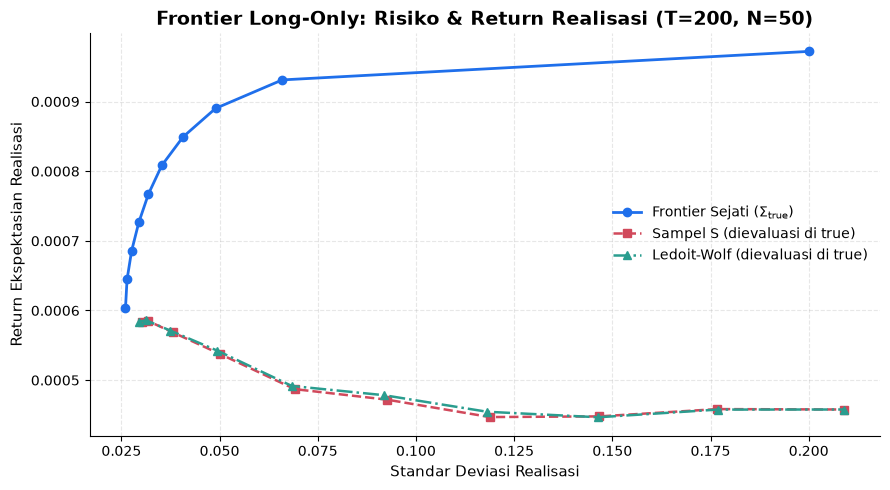

Total waktu eksekusi notebook: 3.42 detik (< 180 detik)


In [6]:
w_cf, var_cf = cov.gmv_closed_form(Sigma_true)
w_num, var_num = cov.gmv_numerical(Sigma_true)
max_w_diff = float(np.max(np.abs(w_cf - w_num)))
print(f"Selisih maks |w_closed_form - w_SLSQP| = {max_w_diff:.3e}")
print(f"Selisih varians |var_cf - var_SLSQP|   = {abs(var_cf - var_num):.3e}")

_, var_lo_true = cov.long_only_gmv(Sigma_true)
print(f"GMV long-only var ({var_lo_true:.8f}) >= GMV unconstrained ({var_cf:.8f})? {var_lo_true >= var_cf - 1e-12}")
print(f"Bobot unconstrained min = {w_cf.min():.6f} (semua >= 0? {bool(np.all(w_cf >= -1e-12))})")

mu_est = rets_single.mean(axis=0)
s_sample = cov.sample_covariance(rets_single, ddof=1)

fr_true = cov.long_only_frontier(Sigma_true, mu, Sigma_true, mu, n_points=10)
fr_samp = cov.long_only_frontier(s_sample, mu_est, Sigma_true, mu, n_points=10)
fr_lw = cov.long_only_frontier(sigma_lw_single, mu_est, Sigma_true, mu, n_points=10)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(fr_true["realized_std"], fr_true["realized_ret"], "o-", lw=2, label=r"Frontier Sejati ($\Sigma_{\mathrm{true}}$)")
ax.plot(fr_samp["realized_std"], fr_samp["realized_ret"], "s--", lw=1.8, label="Sampel S (dievaluasi di true)")
ax.plot(fr_lw["realized_std"], fr_lw["realized_ret"], "^-.", lw=1.8, label="Ledoit-Wolf (dievaluasi di true)")
ax.set_title("Frontier Long-Only: Risiko & Return Realisasi (T=200, N=50)")
ax.set_xlabel("Standar Deviasi Realisasi")
ax.set_ylabel("Return Ekspektasian Realisasi")
ax.legend()
plt.tight_layout()
plotting.save_figure(fig, "day002b_long-only-frontier")
plt.show()

elapsed_total = time.perf_counter() - t_start_all
print(f"Total waktu eksekusi notebook: {elapsed_total:.2f} detik (< 180 detik)")

## Kesimpulan
1. **Bias Wishart yang Tajam**: Pada $N=50, T=200$, estimator sampel $S$ menghasilkan varians *in-sample* yang terlalu optimistis ($\approx 0.7538\,\Sigma_{\min}$, tepat mengikuti $\chi^2_{T-N}/(T-1)$), sementara risiko *realized* di luar sampel melonjak menjadi $\approx 1.329\,\Sigma_{\min}$ sesuai prediksi Okhrin–Schmid $\frac{T-2}{T-N-1}$.
2. **Spektrum Marchenko–Pastur & Kutukan Dimensi**: Nilai eigen matriks korelasi *noise* murni tersebar di $[(1-\sqrt{q})^2, (1+\sqrt{q})^2]$; saat $q = N/T$ meningkat ke $0.75$ ($N=150$), kondisi matriks $S$ membengkak dan varians *realized* melonjak ke $\approx 4.04\,\Sigma_{\min}$.
3. **Efektivitas Ledoit–Wolf**: *Shrinkage* analitik menuju target identitas menjaga matriks tetap positif-definit dengan *trace* terjaga, memangkas risiko *out-of-sample* secara konsisten dibanding $S$, dan menghasilkan frontier *long-only* yang jauh lebih dekat ke frontier sejati.

## Referensi
- Muirhead, R. J. (1982). *Aspects of Multivariate Statistical Theory*. Wiley.
- Okhrin, Y., & Schmid, W. (2006). Distributional properties of portfolio weights. *Journal of Econometrics*, 134(1), 235–256.
- Ledoit, O., & Wolf, M. (2004). A well-conditioned estimator for large-dimensional covariance matrices. *Journal of Multivariate Analysis*, 88(2), 365–411.
- Marchenko, V. A., & Pastur, L. A. (1967). Distribution of eigenvalues for some sets of random matrices. *Mathematics of the USSR-Sbornik*, 1(4), 457–483.